# 21 — Curves and Surfaces

Following the organization of Loring W. Tu, *Differential Geometry: Connections, Curvature, and Characteristic Classes*, Chapter 1, §§2–3. The aim is to connect definitions to geometric intuition and visual experiments.

**Learning goals:** understand regular curves and arc length; compute signed curvature; distinguish principal, mean, and Gaussian curvature; explain Gauss's Theorema Egregium; and interpret Gauss–Bonnet as a relation between curvature and topology.

**Convention.** For surfaces, use the shape operator $S=-dN$. Reversing the chosen unit normal reverses the signs of principal and mean curvature, but not Gaussian curvature. 

## 2.1 Regular Curves

A parametrized curve is a smooth map
$$
\gamma:I\to\mathbb R^n,\qquad t\mapsto\gamma(t).
$$
It is **regular** if $\gamma'(t)\ne0$ for every $t\in I$. The velocity $\gamma'(t)$ determines the tangent line at $\gamma(t)$, and the first-order approximation is
$$
\gamma(t+h)=\gamma(t)+h\gamma'(t)+o(h).
$$
Regularity ensures that this linear approximation has a nonzero direction.

**Example.** $\gamma(t)=(R\cos t,R\sin t)$ is regular because $\|\gamma'(t)\|=R>0$.

**Non-example.** $\eta(t)=(t^3,t^6)$ has $\eta'(0)=(0,0)$ and is not regular at $0$. Regularity is a property of a parametrization, not merely of its image.

**What the code demonstrates:** compare the image of a circle with a parametrization whose velocity vanishes at the origin, and plot the corresponding speeds.

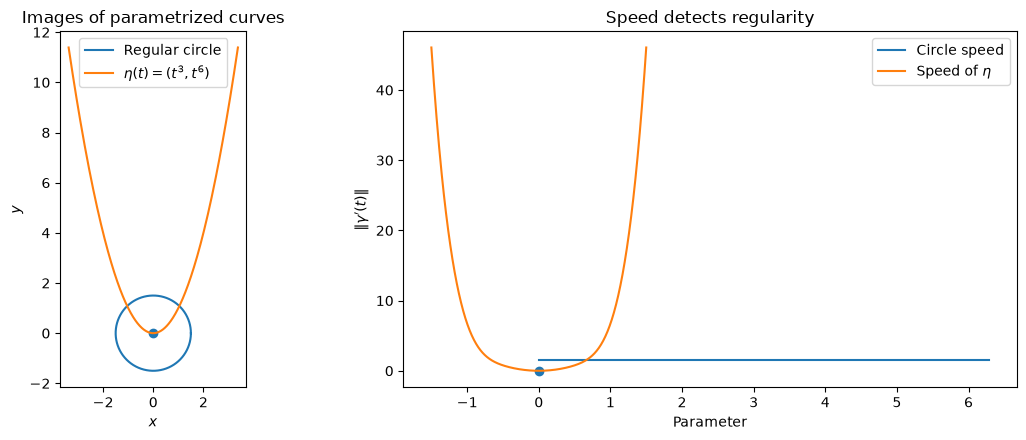

In [1]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(-1.5, 1.5, 500)
u = np.linspace(0, 2*np.pi, 500)
R = 1.5
eta_x, eta_y = t**3, t**6
eta_speed = np.sqrt((3*t**2)**2 + (6*t**5)**2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(R*np.cos(u), R*np.sin(u), label="Regular circle")
ax[0].plot(eta_x, eta_y, label=r"$\eta(t)=(t^3,t^6)$")
ax[0].scatter([0], [0])
ax[0].set_aspect("equal"); ax[0].set_xlabel("$x$"); ax[0].set_ylabel("$y$")
ax[0].set_title("Images of parametrized curves"); ax[0].legend()
ax[1].plot(u, np.full_like(u, R), label="Circle speed")
ax[1].plot(t, eta_speed, label=r"Speed of $\eta$")
ax[1].scatter([0], [0]); ax[1].set_xlabel("Parameter"); ax[1].set_ylabel(r"$\|\gamma'(t)\|$")
ax[1].set_title("Speed detects regularity"); ax[1].legend()
plt.tight_layout(); plt.show()

**Exercises**
1. Verify that $(a\cos t,b\sin t)$ is regular when $a,b>0$.
2. Find the parameter values where $\alpha(t)=(t^2,t^3)$ is not regular.
3. Explain why two parametrizations can have the same image but different speeds.

## 2.2 Arc Length Parametrization

The length of a regular curve $\gamma:[a,b]\to\mathbb R^n$ is
$$
L(\gamma)=\int_a^b\|\gamma'(t)\|\,dt.
$$
Define accumulated arc length by
$$
s(t)=\int_a^t\|\gamma'(u)\|\,du.
$$
Since $ds/dt=\|\gamma'(t)\|>0$, arc length can be used locally as a new parameter. The reparametrized curve $\widetilde\gamma(s)$ has unit speed:
$$
\left\|\frac{d\widetilde\gamma}{ds}\right\|=1.
$$
Arc length removes arbitrary variation in speed but does not erase the direction of traversal. For a circle $\gamma(t)=(R\cos t,R\sin t)$, $s=Rt$ and
$$
\widetilde\gamma(s)=\left(R\cos\frac{s}{R},R\sin\frac{s}{R}\right).
$$

**What the code demonstrates:** two parametrizations trace the same circle, but the second changes its speed along the trace.

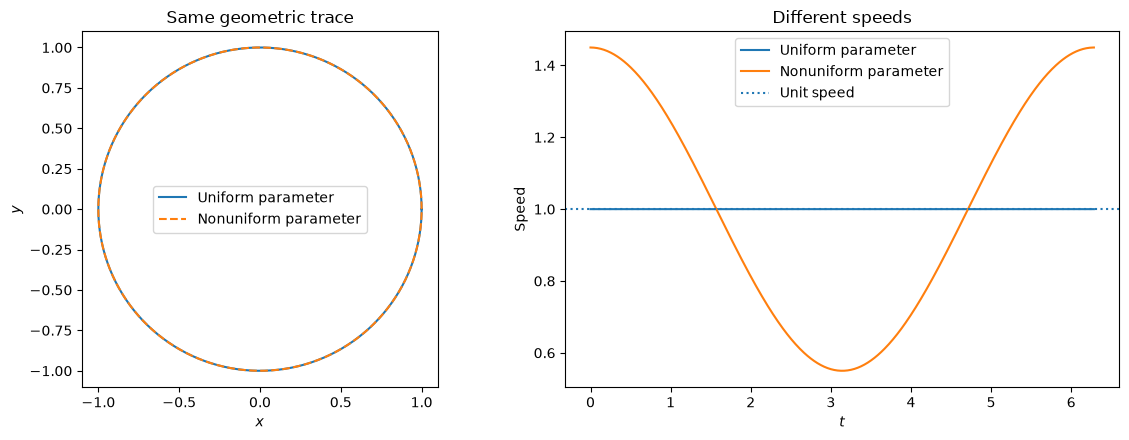

In [2]:
t = np.linspace(0, 2*np.pi, 600)
phi = t + 0.45*np.sin(t)
x1, y1 = np.cos(t), np.sin(t)
x2, y2 = np.cos(phi), np.sin(phi)
v1 = np.sqrt(np.gradient(x1, t)**2 + np.gradient(y1, t)**2)
v2 = np.sqrt(np.gradient(x2, t)**2 + np.gradient(y2, t)**2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(x1, y1, label="Uniform parameter")
ax[0].plot(x2, y2, "--", label="Nonuniform parameter")
ax[0].set_aspect("equal"); ax[0].set_xlabel("$x$"); ax[0].set_ylabel("$y$")
ax[0].set_title("Same geometric trace"); ax[0].legend()
ax[1].plot(t, v1, label="Uniform parameter")
ax[1].plot(t, v2, label="Nonuniform parameter")
ax[1].axhline(1, linestyle=":", label="Unit speed")
ax[1].set_xlabel("$t$"); ax[1].set_ylabel("Speed"); ax[1].set_title("Different speeds"); ax[1].legend()
plt.tight_layout(); plt.show()

**Exercises**
1. Compute the length of a circle of radius $R$.
2. Find an arc-length parametrization of a line with nonzero constant velocity.
3. Explain why unit speed simplifies the definition of curvature.

## 2.3 Signed Curvature of a Plane Curve

For a unit-speed plane curve $\gamma(s)$, the unit tangent is $T=\gamma'(s)$. Since $\langle T,T\rangle=1$, differentiation gives $\langle T',T\rangle=0$. Thus $T'$ is perpendicular to $T$. Let $J(x,y)=(-y,x)$ be counterclockwise rotation by $90^\circ$. There is a scalar $\kappa$ with
$$
T'(s)=\kappa(s)J(T(s)).
$$
The scalar $\kappa$ is the **signed curvature**. For a regular, not necessarily unit-speed curve $\gamma(t)=(x(t),y(t))$,
$$
\boxed{\kappa(t)=\frac{x'y''-y'x''}{(x'^2+y'^2)^{3/2}}.}
$$
The numerator is an oriented determinant; the denominator corrects for parameter speed. A circle of radius $R$ traversed counterclockwise has $\kappa=1/R$, while clockwise traversal has $\kappa=-1/R$.

**What the code demonstrates:** reversing the traversal of a circle reverses signed curvature, even though the geometric image is unchanged.

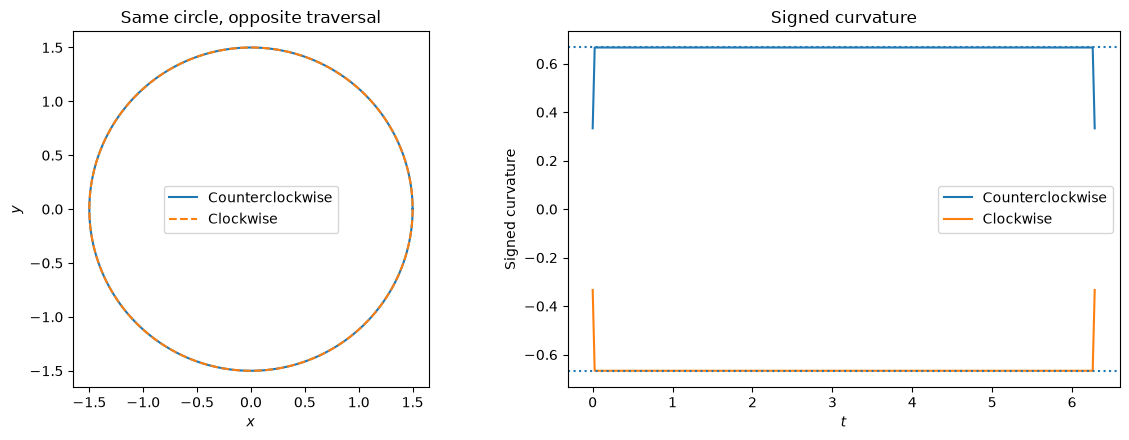

Median CCW curvature: 0.6666666666666653
Median CW curvature: -0.6666666666666653


In [3]:
R = 1.5
t = np.linspace(0, 2*np.pi, 500)
def signed_curvature(x, y, t):
    dx, dy = np.gradient(x, t), np.gradient(y, t)
    ddx, ddy = np.gradient(dx, t), np.gradient(dy, t)
    return (dx*ddy - dy*ddx) / (dx**2 + dy**2)**1.5

x1, y1 = R*np.cos(t), R*np.sin(t)
x2, y2 = R*np.cos(-t), R*np.sin(-t)
k1, k2 = signed_curvature(x1, y1, t), signed_curvature(x2, y2, t)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(x1, y1, label="Counterclockwise")
ax[0].plot(x2, y2, "--", label="Clockwise")
ax[0].set_aspect("equal"); ax[0].set_xlabel("$x$"); ax[0].set_ylabel("$y$")
ax[0].set_title("Same circle, opposite traversal"); ax[0].legend()
ax[1].plot(t, k1, label="Counterclockwise")
ax[1].plot(t, k2, label="Clockwise")
ax[1].axhline(1/R, linestyle=":"); ax[1].axhline(-1/R, linestyle=":")
ax[1].set_xlabel("$t$"); ax[1].set_ylabel("Signed curvature")
ax[1].set_title("Signed curvature"); ax[1].legend()
plt.tight_layout(); plt.show()
print("Median CCW curvature:", np.median(k1[5:-5]))
print("Median CW curvature:", np.median(k2[5:-5]))

**Exercises**
1. Compute the signed curvature of a circle of radius $R$.
2. Compute the curvature of $\gamma(t)=(t,t^2)$ at $t=0$.
3. Identify why orientation reversal changes the sign of signed curvature.

## 2.4 Orientation and Curvature

Signed curvature depends on orientation conventions. With the standard orientation of the plane and $J(x,y)=(-y,x)$, counterclockwise turning is positive. Reversing the direction of traversal changes $\kappa$ to $-\kappa$. Reversing the orientation convention of the plane also reverses its sign. The magnitude $|\kappa|=\|T'(s)\|$ does not depend on these choices.

Signed curvature therefore records more information than bending magnitude: it records the direction in which the tangent turns.

**What the code demonstrates:** signed curvature changes sign under reversal, while unsigned curvature remains the same.

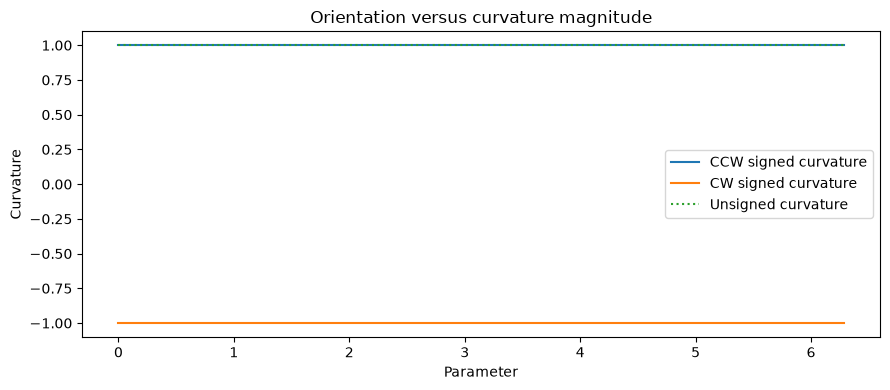

In [4]:
t = np.linspace(0, 2*np.pi, 300)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t, np.ones_like(t), label="CCW signed curvature")
ax.plot(t, -np.ones_like(t), label="CW signed curvature")
ax.plot(t, np.ones_like(t), linestyle=":", label="Unsigned curvature")
ax.set_xlabel("Parameter"); ax.set_ylabel("Curvature")
ax.set_title("Orientation versus curvature magnitude"); ax.legend()
plt.tight_layout(); plt.show()

**Exercises**
1. Distinguish signed curvature from curvature magnitude.
2. What changes if the normal quarter-turn $J$ is replaced by clockwise rotation?

## 3.1 Principal, Mean, and Gaussian Curvatures

Let $S\subset\mathbb R^3$ be a smooth surface with unit normal $N$. With the convention
$$
S_p=-dN_p:T_pS\to T_pS,
$$
the shape operator is self-adjoint. Its eigenvalues $k_1,k_2$ are the **principal curvatures**; eigenvectors are principal directions. Define
$$
H=\frac{k_1+k_2}{2},\qquad K=k_1k_2.
$$
Thus $H=\frac12\operatorname{tr}(S)$ is the **mean curvature**, and $K=\det(S)$ is the **Gaussian curvature**.

- $K>0$: principal curvatures have the same sign; the point is elliptic.
- $K<0$: they have opposite signs; the point is hyperbolic (saddle-like).
- $K=0$: at least one principal curvature is zero.
- $H=0$: the surface is minimal at that point.

For a sphere of radius $R$ with outward normal, this sign convention gives $k_1=k_2=-1/R$, so $H=-1/R$ and $K=1/R^2$. Reversing the normal reverses $H$ but leaves $K$ unchanged.

**What the code demonstrates:** compare a sphere, whose Gaussian curvature is positive, with a saddle, whose Gaussian curvature is negative near the origin.

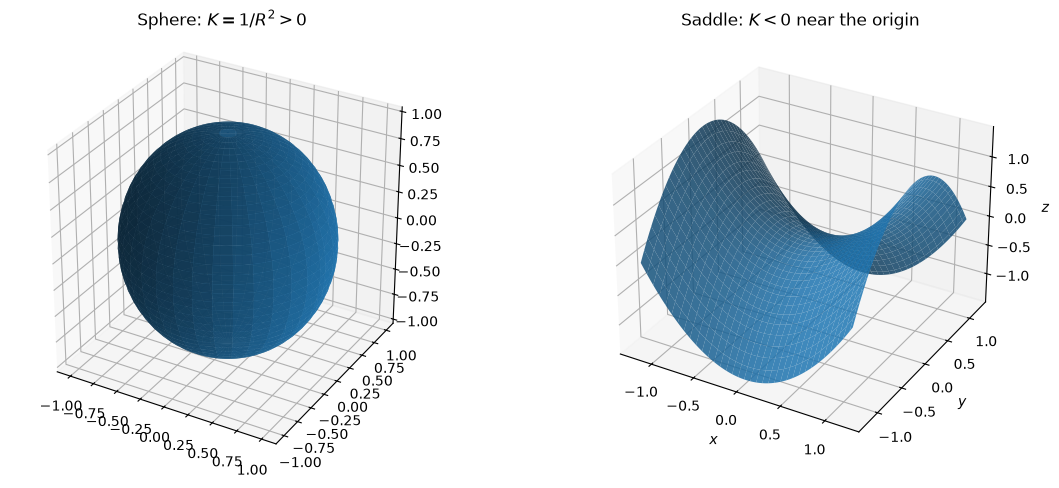

In [5]:
from mpl_toolkits.mplot3d import Axes3D  # enables 3D projection

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
u = np.linspace(0, 2*np.pi, 70); v = np.linspace(0, np.pi, 40)
U, V = np.meshgrid(u, v)
ax1.plot_surface(np.cos(U)*np.sin(V), np.sin(U)*np.sin(V), np.cos(V), alpha=0.85)
ax1.set_title(r"Sphere: $K=1/R^2>0$"); ax1.set_box_aspect((1, 1, 1))
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
x = np.linspace(-1.2, 1.2, 70); y = np.linspace(-1.2, 1.2, 70)
X, Y = np.meshgrid(x, y)
ax2.plot_surface(X, Y, X**2-Y**2, alpha=0.85)
ax2.set_title("Saddle: $K<0$ near the origin")
ax2.set_xlabel("$x$"); ax2.set_ylabel("$y$"); ax2.set_zlabel("$z$")
plt.tight_layout(); plt.show()

**Exercises**
1. If $k_1=2$ and $k_2=-3$, compute $H$ and $K$ and classify the point.
2. Why is Gaussian curvature independent of the choice of unit normal?
3. What does $H=0$ mean geometrically?

## 3.2 Gauss's Theorema Egregium

**Gauss's Theorema Egregium** states that Gaussian curvature is intrinsic: it is determined by the metric on the surface and does not depend on the particular isometric embedding in $\mathbb R^3$.

For a parametrization $r(u,v)$, the induced metric (first fundamental form) is
$$
I=E\,du^2+2F\,du\,dv+G\,dv^2,
$$
where $E=\langle r_u,r_u\rangle$, $F=\langle r_u,r_v\rangle$, and $G=\langle r_v,r_v\rangle$. Gaussian curvature can be recovered from this metric. Hence local isometries preserve $K$.

A plane and a cylinder are locally isometric: a cylindrical patch can be unrolled without stretching, and both have $K=0$. A sphere has positive Gaussian curvature and cannot be flattened locally without distortion. The theorem does not say all extrinsic geometry is intrinsic; mean curvature generally depends on the embedding.

**What the code demonstrates:** the plane and cylinder have zero Gaussian curvature, unlike the sphere. The surfaces are shown to emphasize that an embedding can change while intrinsic geometry is preserved.

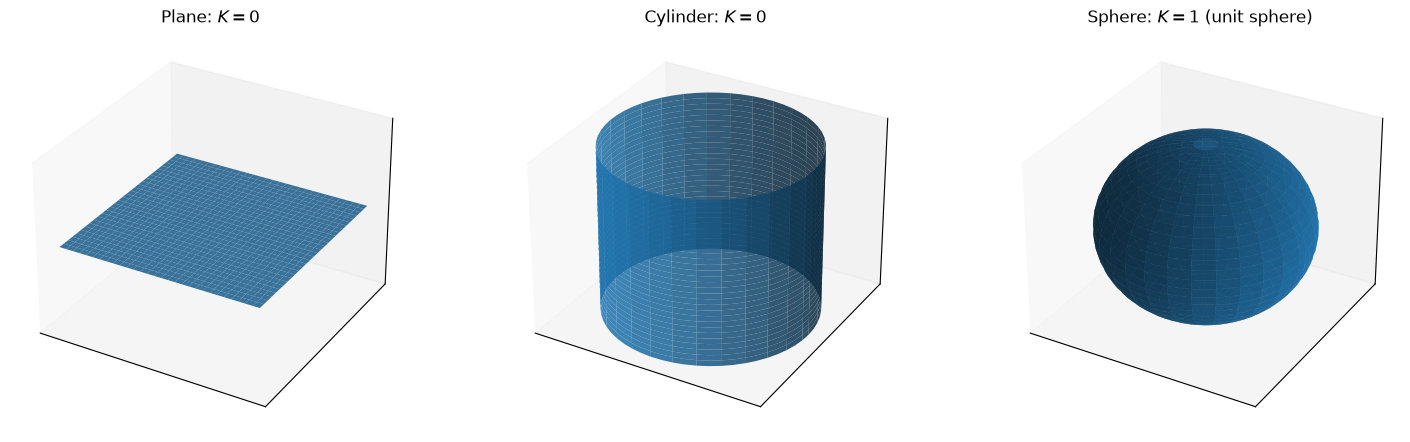

In [6]:
fig = plt.figure(figsize=(15, 4.5))
# Plane
ax = fig.add_subplot(1, 3, 1, projection="3d")
u = np.linspace(-1, 1, 30); U, V = np.meshgrid(u, u)
ax.plot_surface(U, V, np.zeros_like(U), alpha=0.85)
ax.set_title("Plane: $K=0$")
# Cylinder
ax = fig.add_subplot(1, 3, 2, projection="3d")
theta = np.linspace(0, 2*np.pi, 60); z = np.linspace(-1, 1, 30)
T, Z = np.meshgrid(theta, z)
ax.plot_surface(np.cos(T), np.sin(T), Z, alpha=0.85)
ax.set_title("Cylinder: $K=0$")
# Sphere
ax = fig.add_subplot(1, 3, 3, projection="3d")
T, P = np.meshgrid(theta, np.linspace(0, np.pi, 30))
ax.plot_surface(np.cos(T)*np.sin(P), np.sin(T)*np.sin(P), np.cos(P), alpha=0.85)
ax.set_title("Sphere: $K=1$ (unit sphere)")
for a in fig.axes:
    a.set_xticks([]); a.set_yticks([]); a.set_zticks([])
plt.tight_layout(); plt.show()

**Exercises**
1. Explain why a cylinder can be unrolled without stretching.
2. Why does positive Gaussian curvature obstruct a local isometry from a spherical patch to a planar patch?
3. Is mean curvature intrinsic? Explain.

## 3.3 The Gauss–Bonnet Theorem

For a compact, oriented Riemannian surface $M$ with piecewise-smooth boundary, Gauss–Bonnet states
$$
\int_M K\,dA+\int_{\partial M}k_g\,ds+\sum_{j=1}^m\theta_j
=2\pi\chi(M),
$$
where $K$ is Gaussian curvature, $k_g$ is signed geodesic curvature along smooth boundary segments, $\theta_j$ are signed exterior corner angles, and $\chi(M)$ is the Euler characteristic.

For a closed surface, the boundary terms vanish:
$$
\boxed{\int_M K\,dA=2\pi\chi(M).}
$$
For a sphere, $\chi(S^2)=2$, so total Gaussian curvature is $4\pi$. For a torus, $\chi(T^2)=0$, so total Gaussian curvature is zero, although $K$ is not identically zero. In the plane, $K=0$, and the theorem gives the total turning angle $2\pi$ for a positively oriented simple closed curve.

This is a central bridge between local differential geometry and global topology.

**Exercises**
1. Apply Gauss–Bonnet to a sphere of radius $R$. Why is the total curvature independent of $R$?
2. What does Gauss–Bonnet imply about the total Gaussian curvature of a torus?
3. Explain how the total turning angle theorem for a plane curve follows from Gauss–Bonnet.
4. Why are corner-angle terms needed for a piecewise-smooth boundary?

## Summary

Regularity gives a nonzero tangent; arc length removes arbitrary speed; signed curvature measures turning; principal curvatures describe bending in distinguished tangent directions; Gaussian curvature is intrinsic; and Gauss–Bonnet relates its integral to Euler characteristic.

## Reference

Loring W. Tu, *Differential Geometry: Connections, Curvature, and Characteristic Classes*, Chapter 1, §§2–3, Graduate Texts in Mathematics 275, Springer, 2017. See the [official Springer page](https://link.springer.com/book/10.1007/978-3-319-55084-8).